# EfficientNet-B0 (DSO 2), version 2


## 1. Import

In [3]:
import os, time                                   # os : chemins et dossiers ; time : mesurer le temps
import numpy as np                                # calculs sur les tableaux (masques)
import pandas as pd                               # tableaux de données (etiquettes.csv)
import matplotlib.pyplot as plt                   # graphiques et affichage d'images
from PIL import Image                             # ouvrir les images et les masques
from scipy import ndimage                         # séparer les objets d'un masque
import torch                                      # PyTorch : la bibliothèque de deep learning
import torch.nn as nn                             # couches du réseau (Linear, ReLU, Dropout...) et pertes
from torch.utils.data import Dataset, DataLoader  # Dataset : donne une image ; DataLoader : fait des paquets
from torchvision import models, transforms        # modèles pré-entraînés et transformations d'images
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay   # scores

DOSSIER = "."   # dossier du projet (contenant frames/ ou RoadAnomaly/)
if not os.path.isdir(os.path.join(DOSSIER, "frames")):    # si "frames" n'est pas directement dedans...
    DOSSIER = os.path.join(DOSSIER, "RoadAnomaly")        # ...on descend d'un niveau
PREP = os.path.join(DOSSIER, "frames", "DataPreparation") # données préparées (train / val / test)

torch.manual_seed(42)                                     # même hasard à chaque exécution = résultats reproductibles
device = "cuda" if torch.cuda.is_available() else "cpu"  # GPU s'il existe, sinon CPU
print("Appareil :", device)                               # affiche l'appareil utilisé

Appareil : cpu


**Explication :** mêmes imports et mêmes chemins que la version 1, plus `scipy.ndimage` pour séparer les objets d'un masque. On lit toujours les données de `DataPreparation`, avec le même découpage train / val / test, pour pouvoir comparer les deux versions honnêtement.

## 2. La cause : le décor prend presque toute l'image

In [6]:
CLASSES = ["animals", "obstacles", "cones"]                         # les 3 classes à prédire
etiquettes = pd.read_csv(f"{PREP}/etiquettes.csv")                  # nom, classe, photo d'origine et ensemble de chaque image
etiquettes["label"] = etiquettes["classe"].map({c: i for i, c in enumerate(CLASSES)})   # transforme classe -> nombre : animals=0, obstacles=1, cones=2  :Le modèle ne comprend pas les mots, seulement les nombres

etiquettes["anomalie_%"] = [                                        # % de l'image occupé par l'anomalie
    (np.array(Image.open(f"{PREP}/{e}/masques/{n}.png")) > 0).mean() * 100   # On obtient une nouvelle colonne anomalie_% : la taille de l’objet dans chaque image.
    for n, e in zip(etiquettes.nom, etiquettes.ensemble)            
]
print(etiquettes.groupby("classe")["anomalie_%"].mean().round(1))   # taille moyenne de l'anomalie par classe
print("Photos d'origine par ensemble :")
print(etiquettes.groupby("ensemble")["source"].nunique())           # nombre de photos d'origine dans train / val / test

classe
animals      12.6
cones         2.8
obstacles     9.5
Name: anomalie_%, dtype: float64
Photos d'origine par ensemble :
ensemble
test      9
train    37
val       8
Name: source, dtype: int64


le décor fait environ 90 % de l’image et il est répété 19 fois. Le modèle apprend donc le décor au lieu de l’objet : c’est la cause du surapprentissage

## 3. Solution 1 : recadrer sur l'anomalie

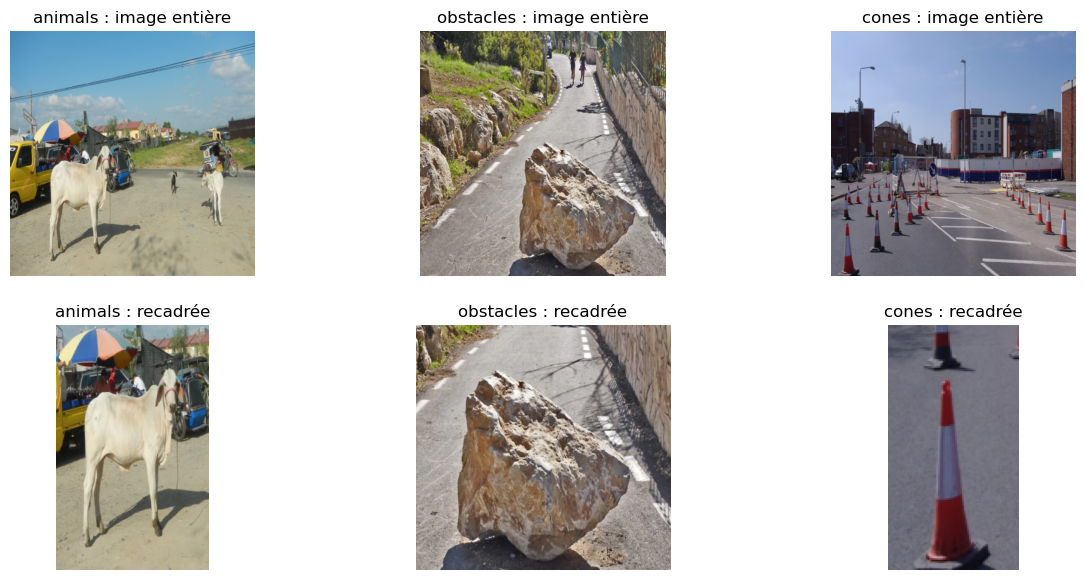

In [9]:
def recadrer(nom, ensemble, marge=0.2):                              # découpe l'image autour de l'anomalie
    img = Image.open(f"{PREP}/{ensemble}/images/{nom}.png").convert("RGB")       # image en couleur
    masque = np.array(Image.open(f"{PREP}/{ensemble}/masques/{nom}.png")) > 0    
    objets, n = ndimage.label(masque)                                #séparer les objets
    if n == 0:                                                       # aucun objet dans le masque...
        return img                                                   
    tailles = ndimage.sum(masque, objets, range(1, n + 1))           #On compte combien de pixels a chaque objet
    ys, xs = np.where(objets == np.argmax(tailles) + 1)              # coordonnées des pixels du plus grand objet
    x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()          # trouver les 4 bords de l’objet :On a le rectangle qui entoure l’objet
    dx, dy = int((x1 - x0) * marge) + 10, int((y1 - y0) * marge) + 10   # marge de 20 % de taille d'objet (+ 10 pixels) On veut agrandir un peu le rectangle, pour ne pas couper l’objet trop serré.
    return img.crop((max(x0 - dx, 0), max(y0 - dy, 0), min(x1 + dx, img.width), min(y1 + dy, img.height)))   # découpe le rectangle

fig, ax = plt.subplots(2, 3, figsize=(15, 7))                        # grille 2 lignes x 3 colonnes
for i, c in enumerate(CLASSES):                                      # une colonne par classe
    ligne = etiquettes[(etiquettes.classe == c) & (etiquettes.ensemble == "train")].iloc[0]   # première image train de la classe
    ax[0, i].imshow(Image.open(f"{PREP}/train/images/{ligne.nom}.png")); ax[0, i].set_title(f"{c} : image entière")   # en haut : image entière
    ax[1, i].imshow(recadrer(ligne.nom, "train")); ax[1, i].set_title(f"{c} : recadrée")                                # en bas : image recadrée
    ax[0, i].axis("off"); ax[1, i].axis("off")                       # cache les axes
plt.show()

Explication : la fonction cherche l’objet dans le masque, garde le plus grand, dessine un rectangle autour, ajoute une marge de 20 % et découpe l’image

## 4. Solution 2 : chargement des données avec variations aléatoires

In [12]:
NORMALISATION = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])   # moyenne / écart-type ImageNet (R, G, B)

transformation_train = transforms.Compose([                  # transformations du train (avec hasard)
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),       # zoom au hasard (70 à 100 %) puis 224 x 224
    transforms.RandomHorizontalFlip(),                         # retourne l'image au hasard (1 fois sur 2) droite gauche
    transforms.ColorJitter(0.3, 0.3, 0.3),                     # lumière / contraste / couleurs au hasard
    transforms.ToTensor(),                                     # image -> tenseur, pixels 0..255 -> 0..1 C’est un tableau de nombres
    NORMALISATION,                                             # normalisation ImageNet
])                                         #Le hasard est tiré à chaque fois qu’une image est chargée, donc à chaque époque. Le modèle ne voit jamais deux fois exactement la même image
transformation = transforms.Compose([                         # validation et test : pas de hasard
    transforms.Resize((224, 224)),                             #  la taille d’entraînement d’EfficientNet-B0
    transforms.ToTensor(),                                     # image -> tenseur 0..1
    NORMALISATION,                                             # normalisation ImageNet
])

class RoadDataset(Dataset):                                    #RoadDataset explique à PyTorch comment lire nos images. Pour chaque groupe (train, val ou test)
    def __init__(self, ensemble):
        self.ensemble = ensemble
        self.df = etiquettes[etiquettes.ensemble == ensemble].reset_index(drop=True)   
        self.t = transformation_train if ensemble == "train" else transformation      
    def __len__(self):                                        
        return len(self.df)
    def __getitem__(self, i):                                 
        ligne = self.df.iloc[i]
        return self.t(recadrer(ligne.nom, self.ensemble)), ligne.label  

train_ds, val_ds, test_ds = RoadDataset("train"), RoadDataset("val"), RoadDataset("test")   # les 3 ensembles
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)  # paquets de 32, mélangés à chaque époque:mélanger au hasard
val_dl = DataLoader(val_ds, batch_size=32)                   
test_dl = DataLoader(test_ds, batch_size=32)
print(len(train_ds), "images train,", len(val_ds), "val,", len(test_ds), "test")  

698 images train, 139 val, 163 test


__init__ garde la liste des images de son groupe (train, val ou test). __len__ donne le nombre d’images du groupe. Le DataLoader demande une image par son numéro, et __getitem__ renvoie l’image prête avec sa réponse. Le DataLoader fait ensuite des paquets de 32 images pour le modèle ,Il reçoit un groupe de 32 images en même temps (batch size =32).

Un tenseur est un tableau de nombres que PyTorch comprend, et c’est le seul format que le modèle accepte
PyTorch: construire et entraîner le modèle

## 5. Création du modèle

In [15]:
model = models.efficientnet_b0(weights="IMAGENET1K_V1")  # EfficientNet-B0 avec les poids déjà appris sur ImageNet (1000 classes)
model.classifier = nn.Sequential(                         # on remplace la tête d'origine (1000 classes) par la nôtre
    nn.Linear(1280, 256),   #                             256 N couche fully connected /Le backbone (la grande partie d’EfficientNet qui « regarde » l’image) transforme l’image en un résumé de 1280 nombres
    nn.ReLU(),              # Activation
    nn.Dropout(0.5),       
    nn.Linear(256, 3),      # Output Elle transforme les 256 nombres en 3 scores, un par classe,
)
model = model.to(device)                                  # envoie le modèle sur le GPU ou le CPU
print(model.classifier)                                   # affiche la nouvelle tête

Sequential(
  (0): Linear(in_features=1280, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=256, out_features=3, bias=True)
)


chaque image est résumée en 1280 nombres (par le backbone) ;
ces 1280 nombres vont dans 256 neurones ;
chaque neurone reçoit les 1280 nombres

## 6. Architecture

In [18]:
couches = pd.Series([type(m).__name__ for m in model.modules()]).value_counts()   # prouver que le modèle contient bien les 5 étapes imposées (convolution, activation, pooling, fully connected, output) et à montrer qu’il est léger (4,3 millions de poids).
print(couches[["Conv2d", "SiLU", "AdaptiveAvgPool2d", "Linear", "ReLU"]])      #combien de couches de chaque type
print("Paramètres :", round(sum(p.numel() for p in model.parameters()) / 1e6, 1), "millions")   

Conv2d               81
SiLU                 49
AdaptiveAvgPool2d    17
Linear                2
ReLU                  1
Name: count, dtype: int64
Paramètres : 4.3 millions


## 7. 2 FONCTION explique comment entraîner le modèle pendant une époque

In [21]:
critere = nn.CrossEntropyLoss(label_smoothing=0.1)      # Elle mesure à quel point le modèle se trompe. Elle transforme d’abord les 3 scores en probabilités (avec Softmax), puis regarde la probabilité donnée à la bonne classe

def entrainer_une_epoque(model, dl, optimiseur):         # un passage complet sur le train
    model.train()                                         # mode entraînement (Dropout actif)
    perte_totale, bons = 0, 0
    for x, y in dl:                                       # pour chaque paquet de 32 images x = les 32 images, y = leurs 32 vraies classes.
        x, y = x.to(device), y.to(device)               
        optimiseur.zero_grad()                            # remet les gradients à zéro
        sortie = model(x)                                 #  marche AVANT : prédire les 32 images
        perte = critere(sortie, y)                        # calculer l'erreur
        perte.backward()                                  # marche ARRIÈRE : calculer les corrections
        optimiseur.step()                                 # applique les corrections aux poids
        perte_totale += perte.item() * len(y)             # additionne la perte du paquet
        bons += (sortie.argmax(1) == y).sum().item()      # compte les bonnes réponses
    return perte_totale / len(dl.dataset), bons / len(dl.dataset)   # perte moyenne et accuracy du train

@torch.no_grad()                                          # pas de calcul de gradients : plus rapide, ne modifie rien
def evaluer(model, dl):                                   # mesure le modèle sur val ou test
    model.eval()                                          # mode évaluation (Dropout éteint)
    perte_totale, vrais, preds = 0, [], []
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        sortie = model(x)
        perte_totale += critere(sortie, y).item() * len(y)
        preds += sortie.argmax(1).tolist()                # classe prédite = celle avec le plus grand score
        vrais += y.tolist()                               # vraies classes
    return perte_totale / len(dl.dataset), accuracy_score(vrais, preds), f1_score(vrais, preds, average="macro"), vrais, preds   # perte, accuracy, F1 macro, listes

Le label smoothing empêche la certitude à 100 % entrainer_une_epoque sert à entraîner le modèle.
Pour chaque paquet de 32 images, elle fait : marche avant (prédire) → calcul de l’erreur → marche arrière (calculer les corrections) → correction des poids.
evaluer sert à mesurer le modèle sur la validation et le test. Elle fait seulement la marche avant et calcule les notes (perte, accuracy, F1), sans corriger les poids.
Le bon ordre, en résumé

## 8. Entraînement 1 : seulement la tête

In [24]:
for p in model.features.parameters():
    p.requires_grad = False                    # backbone gelé : ses poids ImageNet ne bougent pas pas de corrections pour ce poids
optimiseur = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=0.01)   #réduit un tout petit peu tous les poids/ entraîne seulement la tête ;
                                                                #learning rate = 0,001 : la taille des pas de correction
historique = []                                # garde les scores de chaque époque pour les courbes
for epoque in range(5):                        # 5 époques
    perte_train, acc_train = entrainer_une_epoque(model, train_dl, optimiseur)   # apprend sur le train
    perte_val, acc_val, f1_val, _, _ = evaluer(model, val_dl)                     # mesure sur la validation
    historique.append({"perte_train": perte_train, "perte_val": perte_val, "acc_train": acc_train, "acc_val": acc_val, "f1_val": f1_val})
    print(f"Époque {epoque + 1} : perte {perte_train:.3f} / {perte_val:.3f}   accuracy {acc_train:.0%} / {acc_val:.0%}   F1 val {f1_val:.2f}")   # train / validation

Époque 1 : perte 0.555 / 0.687   accuracy 89% / 81%   F1 val 0.79
Époque 2 : perte 0.342 / 0.625   accuracy 100% / 86%   F1 val 0.85
Époque 3 : perte 0.326 / 0.577   accuracy 100% / 90%   F1 val 0.90
Époque 4 : perte 0.326 / 0.597   accuracy 100% / 88%   F1 val 0.87
Époque 5 : perte 0.319 / 0.578   accuracy 100% / 92%   F1 val 0.92


## 9. Entraînement 2 : seulement les derniers blocs + early stopping

In [27]:
for p in model.features[6:].parameters():   #à partir du bloc 6 jusqu’à la fin → blocs 6, 7, 8
    p.requires_grad = True                     # on dégèle seulement les 3 derniers blocs du backbone
optimiseur = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-4, weight_decay=0.01)   # lr 10 fois plus petit 0,0001 
entrainables = sum(p.numel() for p in model.parameters() if p.requires_grad)   # nombre de poids entraînés
print("Paramètres entraînés :", round(entrainables / 1e6, 1), "millions")

meilleur_f1, attente, PATIENCE = 0, 0, 5      
for epoque in range(30):                       # 30 époques maximum
    perte_train, acc_train = entrainer_une_epoque(model, train_dl, optimiseur)
    perte_val, acc_val, f1_val, _, _ = evaluer(model, val_dl)
    historique.append({"perte_train": perte_train, "perte_val": perte_val, "acc_train": acc_train, "acc_val": acc_val, "f1_val": f1_val})
    print(f"Époque {epoque + 1} : perte {perte_train:.3f} / {perte_val:.3f}   accuracy {acc_train:.0%} / {acc_val:.0%}   F1 val {f1_val:.2f}")
    if f1_val > meilleur_f1:                   # nouveau meilleur F1 de validation ? on le retient et on remet le compteur à 0
        meilleur_f1, attente = f1_val, 0       
        torch.save(model.state_dict(), "efficientnet_b0_v2.pt")   
    else:
        attente += 1                          
        if attente == PATIENCE:                # 5 époques sans progrès : on arrête (early stopping)
            print("Early stopping : le F1 de validation ne progresse plus")
            break
print("Meilleur F1 de validation :", round(meilleur_f1, 3))

Paramètres entraînés : 3.5 millions
Époque 1 : perte 0.319 / 0.531   accuracy 100% / 97%   F1 val 0.97
Époque 2 : perte 0.314 / 0.478   accuracy 100% / 100%   F1 val 1.00
Époque 3 : perte 0.308 / 0.507   accuracy 100% / 99%   F1 val 0.99
Époque 4 : perte 0.307 / 0.480   accuracy 100% / 100%   F1 val 1.00
Époque 5 : perte 0.310 / 0.431   accuracy 100% / 100%   F1 val 1.00
Époque 6 : perte 0.307 / 0.444   accuracy 100% / 100%   F1 val 1.00
Époque 7 : perte 0.307 / 0.421   accuracy 100% / 100%   F1 val 1.00
Early stopping : le F1 de validation ne progresse plus
Meilleur F1 de validation : 1.0


F1 verifier la précision et le rappel

## 10. Courbes

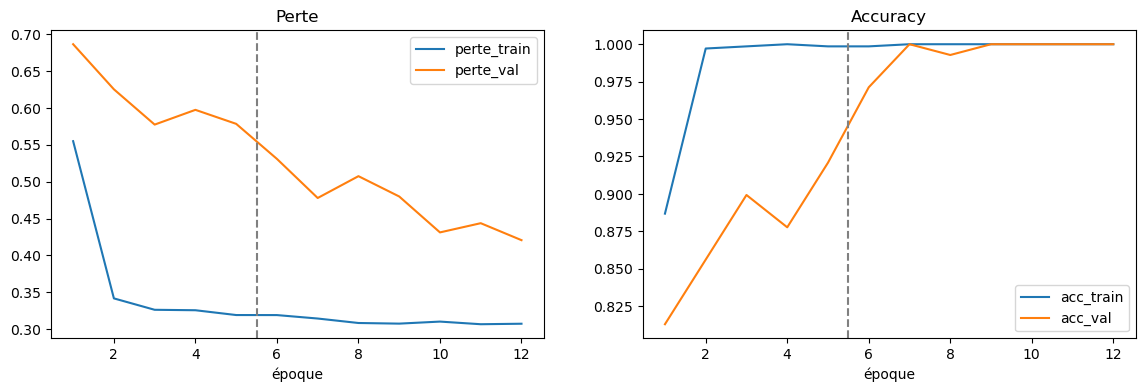

In [30]:
h = pd.DataFrame(historique)                   # scores de toutes les époques dans un tableau
h.index = h.index + 1                          # numéros d'époque à partir de 1
fig, ax = plt.subplots(1, 2, figsize=(14, 4))  # 2 graphiques côte à côte
h[["perte_train", "perte_val"]].plot(ax=ax[0], title="Perte")     #   l'erreur
h[["acc_train", "acc_val"]].plot(ax=ax[1], title="Accuracy")      # % de bonnes réponses
for a in ax:
    a.axvline(5.5, color="gray", linestyle="--")    # ligne grise : fin de l'entraînement 1
    a.set_xlabel("époque")
plt.show()

gauce tete| droite 678 tete 

## 11. Validation / test : par image et par photo d'origine

Validation : accuracy = 100.0%   F1 macro = 1.00   photos bien classées = 100% sur 8
Test : accuracy = 95.1%   F1 macro = 0.95   photos bien classées = 89% sur 9
              precision    recall  f1-score   support

     animals       1.00      0.85      0.92        54
   obstacles       0.89      1.00      0.94        67
       cones       1.00      1.00      1.00        42

    accuracy                           0.95       163
   macro avg       0.96      0.95      0.95       163
weighted avg       0.96      0.95      0.95       163



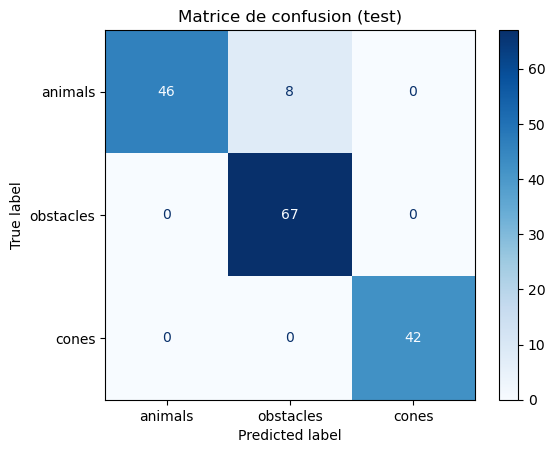

In [33]:
model.load_state_dict(torch.load("efficientnet_b0_v2.pt", map_location=device))   # recharge le meilleur modèle sauvegardé

def score_par_photo(ds, vrais, preds):                       # score par photo d'origine (vote des copies)
    d = ds.df.assign(vrai=vrais, pred=preds)                 # ajoute vraie classe et prédiction à chaque image
    vote = d.groupby("source").agg(vrai=("vrai", "first"), pred=("pred", lambda p: p.mode()[0]))   # classe la plus votée par photo
    return (vote.vrai == vote.pred).mean(), len(vote)        # % de photos bien classées, nombre de photos

for nom, ds, dl in [("Validation", val_ds, val_dl), ("Test", test_ds, test_dl)]:   # validation puis test
    _, acc, f1, vrais, preds = evaluer(model, dl)
    acc_photo, n_photos = score_par_photo(ds, vrais, preds)
    print(f"{nom} : accuracy = {acc:.1%}   F1 macro = {f1:.2f}   photos bien classées = {acc_photo:.0%} sur {n_photos}")

print(classification_report(vrais, preds, target_names=CLASSES))   # précision, rappel, F1 par classe (test)
ConfusionMatrixDisplay(confusion_matrix(vrais, preds), display_labels=CLASSES).plot(cmap="Blues")   # matrice de confusion du test
plt.title("Matrice de confusion (test)")
plt.show()

## 12. Comparaison avec la version 1

In [36]:
_, acc_val, f1_val, _, _ = evaluer(model, val_dl)       # scores de la version 2 sur la validation
_, acc_test, f1_test, _, _ = evaluer(model, test_dl)    # et sur le test
pd.DataFrame({                                           # tableau de comparaison
    "Version 1 (image entière)": [0.849, 0.85, 0.982, 0.98],   # scores copiés de la version 1
    "Version 2 (recadrée)": [round(acc_val, 3), round(f1_val, 2), round(acc_test, 3), round(f1_test, 2)],
}, index=["accuracy val", "F1 val", "accuracy test", "F1 test"])

,Version 1 (image entière),Version 2 (recadrée)
accuracy val,0.849,1.000
F1 val,0.850,1.000
accuracy test,0.982,0.951
F1 test,0.980,0.950
